# Further Tuning of the Descriptor Model

The current best model uses Morgan fingerprints and six molecular descriptors. Here we **keep the representation and precision target fixed**, comparing five prespecified model settings.

1. Current Random Forest with 300 trees — control.
2. Random Forest with 600 trees — average more trees.
3. Random Forest with at least 2 samples per leaf — smooth predictions.
4. Random Forest considering 5% of features per split.
5. Extra Trees with 600 trees and the same enriched inputs.

Objective: training OOF **precision ≥ 90%, then maximum recall**. Dataset, scaffold partitions, and random seed are unchanged. Neither model nor threshold is selected using test results. Select **Run All**.

The test set has already been inspected; this comparison is not new independent validation.

## 1. Validate previous and experimental models

The previous best descriptor model is saved as `herg_descriptor_baseline.joblib`; the new experimental winner is in `herg_tuned_candidate.joblib`. We check dataset identity, partition separation, and reproducibility of selection from OOF scores alone.

In [1]:
from pathlib import Path
from hashlib import sha256
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import (precision_recall_curve, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay)
from rdkit import Chem
from rdkit.Chem import Draw

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir() and (ROOT.parent / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise RuntimeError("Open from the project root or notebooks directory.")
sys.path.insert(0, str(ROOT))
from src.modeling import select_model_at_precision
baseline_path = ROOT / "models/herg_descriptor_baseline.joblib"
active_path = ROOT / "models/herg_tuned_candidate.joblib"
if not baseline_path.is_file() or not active_path.is_file():
    raise FileNotFoundError("Both the saved baseline and selected experiment artifact are required; see README.")
old = joblib.load(baseline_path)  # Only load your own trusted artifacts.
a = joblib.load(active_path)
if a.get("selection_metric") != "recall_at_precision" or not a.get("candidate_thresholds"):
    raise ValueError("Run the policy-aware search with --model-path models/herg_tuned_candidate.joblib first; see README.")
assert a["tuning_search"] and a["include_descriptors"]
assert a["dataset_sha256"] == old["dataset_sha256"] == sha256((ROOT / "data/raw/herg_karim.csv").read_bytes()).hexdigest()
assert a["threshold_selection"]["min_precision"] == old["threshold_selection"]["min_precision"]
target = a["threshold_selection"]["min_precision"]
oof = a["oof_predictions"]
assert oof.row_index.is_unique
assert set(oof.row_index) == set(a["train_indices"])
assert set(oof.row_index).isdisjoint(a["test_predictions"].row_index)
assert set(oof.scaffold).isdisjoint(a["test_predictions"].scaffold)
assert oof.groupby("scaffold").fold.nunique().eq(1).all()
selected_name, candidates = select_model_at_precision(a["cv_metrics"], a["candidate_oof_scores"], oof.label, target)
assert selected_name == a["model_name"]
assert candidates == a["candidate_thresholds"]
assert candidates[selected_name] == a["threshold_selection"]
# The unchanged control must reproduce the previous model's OOF scores.
previous_oof = old["oof_predictions"].set_index("row_index").loc[oof.row_index]
np.testing.assert_allclose(a["candidate_oof_scores"]["Random forest (fingerprints + descriptors)"], previous_oof.score)
assert set(old["test_predictions"].row_index) == set(a["test_predictions"].row_index)
assert set(old["train_indices"]) == set(a["train_indices"])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.18})
display(pd.DataFrame([
    {"Run": "Previous", "Model": old["model_name"], "Threshold": old["decision_threshold"],
     "OOF precision": old["threshold_selection"]["precision"], "OOF recall": old["threshold_selection"]["recall"]},
    {"Run": "Selected", "Model": a["model_name"], "Threshold": a["decision_threshold"],
     "OOF precision": a["threshold_selection"]["precision"], "OOF recall": a["threshold_selection"]["recall"]},
]).set_index("Run"))

,Model,Threshold,OOF precision,OOF recall
Run,,,,
Previous,Random forest (fingerprints + descriptors),0.647325,0.900942,0.587054
Selected,RF descriptors (600 trees),0.642925,0.900000,0.590960


## 2. OOF results for all five candidates

All numbers in this table come from training cross-validation. Each model receives the maximum-recall threshold satisfying the 90% precision constraint; the model is then selected by that recall. Ties prefer mean CV AP, then model name.

Orange marks the selected winner; the vertical dotted line is the previous model's recall. The right chart compares the complete OOF PR curves of the previous and selected models.

,Feasible,OOF precision,OOF recall,Threshold,Mean CV AP,Selected
Model,,,,,,
Random forest (fingerprints + descriptors),True,0.9009,0.5871,0.6473,0.8888,False
RF descriptors (600 trees),True,0.9000,0.5910,0.6429,0.8898,True
RF descriptors (leaf size 2),True,0.9003,0.5558,0.6318,0.8821,False
RF descriptors (5% features),True,0.9006,0.5867,0.6573,0.8905,False
Extra trees descriptors (600 trees),True,0.9001,0.5647,0.6734,0.8792,False


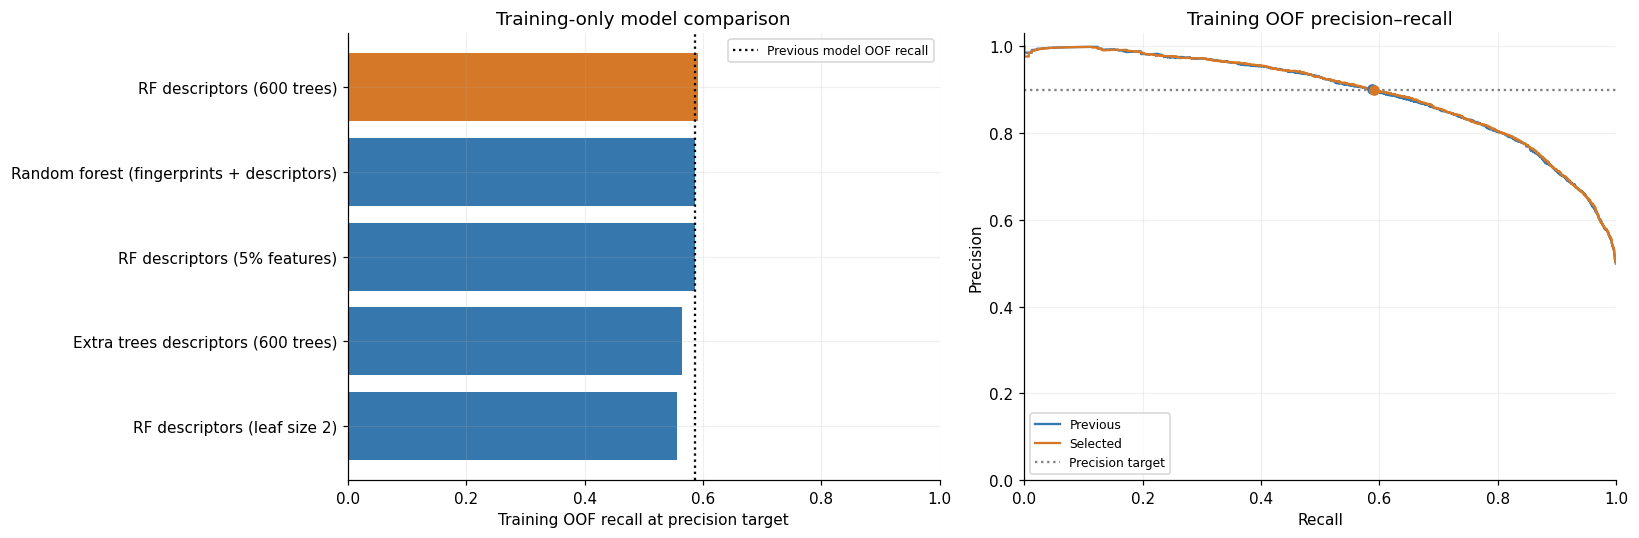

In [2]:
rows = []
for name, policy in candidates.items():
    rows.append({"Model": name, "Feasible": "threshold" in policy,
        "OOF precision": policy.get("precision", np.nan), "OOF recall": policy.get("recall", np.nan),
        "Threshold": policy.get("threshold", np.nan), "Mean CV AP": a["cv_metrics"][name]["auprc"]["mean"],
        "Selected": name == selected_name})
comparison_oof = pd.DataFrame(rows).set_index("Model")
display(comparison_oof.round(4))
valid = comparison_oof[comparison_oof.Feasible].sort_values("OOF recall")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].barh(valid.index, valid["OOF recall"], color=["#d57928" if name == selected_name else "#3677ad" for name in valid.index])
axes[0].axvline(old["threshold_selection"]["recall"], color="black", linestyle=":", label="Previous model OOF recall")
axes[0].set(xlabel="Training OOF recall at precision target", xlim=(0, 1), title="Training-only model comparison")
axes[0].legend(fontsize=8)
for artifact, label, color in [(old, "Previous", "#3677ad"), (a, "Selected", "#d57928")]:
    scores = artifact["oof_predictions"]
    precision, recall, _ = precision_recall_curve(scores.label, scores.score)
    axes[1].step(recall, precision, where="post", label=label, color=color)
    policy = artifact["threshold_selection"]
    axes[1].scatter(policy["recall"], policy["precision"], color=color, zorder=4)
axes[1].axhline(target, color="gray", linestyle=":", label="Precision target")
axes[1].set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.03), title="Training OOF precision–recall")
axes[1].legend(fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()

## 3. Test comparison for the single selected winner

Read precision, recall, and error counts together. Detecting more inhibitors is insufficient if precision drops below the target. Thresholds are not readjusted using these test results.

The best training OOF result is not independent validation, since those results selected both the model settings and threshold.

,Precision,Recall,F1,TN,FP,FN,TP
Run,,,,,,,
Previous precision model,0.9059,0.6453,0.7537,1248,90,476,866
Selected precision model,0.9122,0.6505,0.7595,1254,84,469,873


,Selected minus previous
Precision,0.0064
Recall,0.0052
F1,0.0058
TN,6.0000
FP,-6.0000
FN,-7.0000
TP,7.0000


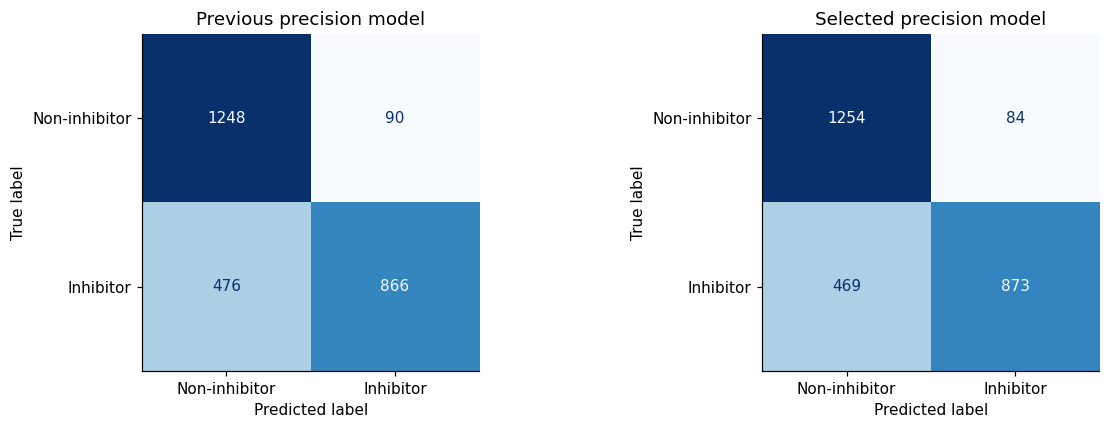

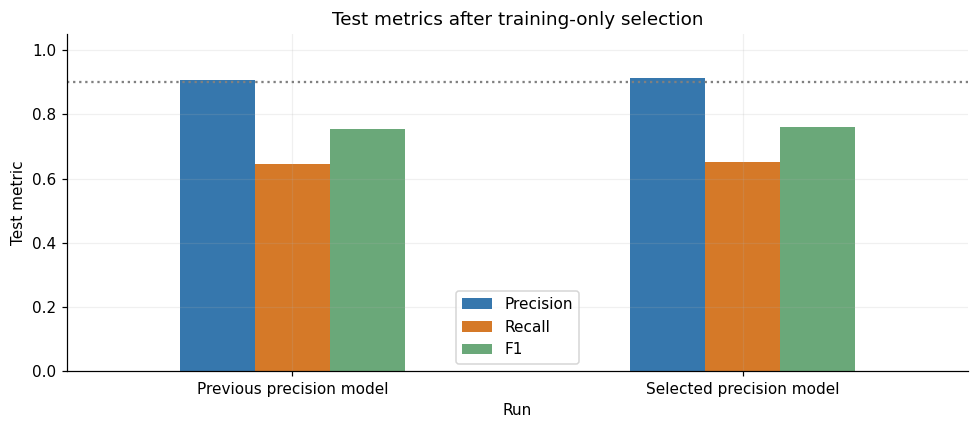

In [3]:
test_rows = []
for name, artifact in [("Previous precision model", old), ("Selected precision model", a)]:
    test = artifact["test_predictions"]
    prediction = test.threshold_prediction
    np.testing.assert_array_equal(prediction, test.score >= artifact["decision_threshold"])
    tn, fp, fn, tp = confusion_matrix(test.label, prediction, labels=[0, 1]).ravel()
    test_rows.append({"Run": name,
        "Precision": precision_score(test.label, prediction, zero_division=0),
        "Recall": recall_score(test.label, prediction, zero_division=0),
        "F1": f1_score(test.label, prediction, zero_division=0),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp})
comparison_test = pd.DataFrame(test_rows).set_index("Run")
display(comparison_test.round(4))
display((comparison_test.iloc[1] - comparison_test.iloc[0]).rename("Selected minus previous").to_frame().round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, title, artifact in zip(axes, ["Previous precision model", "Selected precision model"], [old, a]):
    test = artifact["test_predictions"]
    ConfusionMatrixDisplay.from_predictions(test.label, test.threshold_prediction, labels=[0, 1],
        display_labels=["Non-inhibitor", "Inhibitor"], cmap="Blues", ax=ax, colorbar=False, values_format="d")
    ax.set_title(title)
    ax.grid(False)
fig.tight_layout()
plt.show()
comparison_test[["Precision", "Recall", "F1"]].plot.bar(figsize=(9, 4), rot=0,
    color=["#3677ad", "#d57928", "#6aa879"])
plt.axhline(target, color="gray", linestyle=":")
plt.ylim(0, 1.05)
plt.ylabel("Test metric")
plt.xlabel("Run")
plt.title("Test metrics after training-only selection")
plt.tight_layout()
plt.show()

## 4. Changes for individual compounds

We separately count previously missed inhibitors now detected and previously detected inhibitors now missed. Their difference is the net gain. Below are images of up to six newly detected inhibitors.

,Count
Previously missed inhibitors now detected,10
Previously detected inhibitors now missed,3
Net additional inhibitors detected,7


,row_index,label,previous_prediction,threshold_prediction,score,smiles
314,1501,1,0,1,0.656667,N#Cc1c(-c2ccccc2)cc(-c2ccccc2)nc1/N=C1\S/C(=C2...
353,1653,1,0,1,0.658326,CN1CCc2cccc3c2[C@H]1Cc1ccc(O)c(O)c1-3.Cl
366,1729,1,0,1,0.658333,O=[N+]([O-])c1ccc(S(=O)(=O)N2CCC(CN3CCC(c4noc5...
797,4035,1,0,1,0.665849,CCOC(=O)C1CCN(c2cc(C(=N)N(C)C)ccc2C(=O)Nc2ccc(...
1366,6817,1,0,1,0.649460,Clc1cc(Cl)cc(CN(C2CC2)C2CNC2)c1
1713,8455,1,0,1,0.659734,CC(C)(C)N(CC(O)c1cc(Cl)cc2c1-c1ccc(Cl)cc1/C2=C...


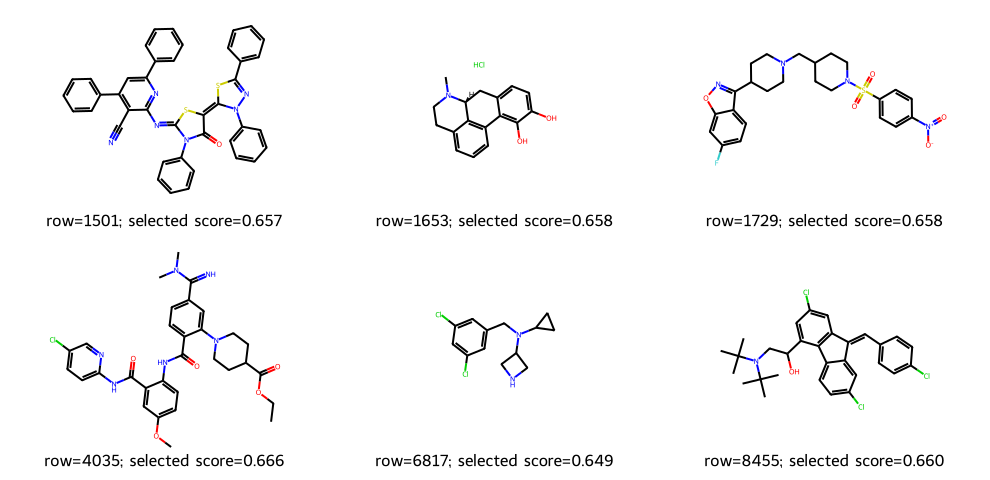

In [4]:
joined = old["test_predictions"][["row_index", "label", "threshold_prediction"]].rename(
    columns={"threshold_prediction": "previous_prediction"}).merge(
    a["test_predictions"][["row_index", "label", "smiles", "score", "threshold_prediction"]],
    on="row_index", how="inner", suffixes=("_old", ""), validate="one_to_one")
assert joined.label_old.eq(joined.label).all()
recovered = joined[(joined.label == 1) & (joined.previous_prediction == 0) & (joined.threshold_prediction == 1)].sort_values("row_index")
new_misses = joined[(joined.label == 1) & (joined.previous_prediction == 1) & (joined.threshold_prediction == 0)]
display(pd.Series({"Previously missed inhibitors now detected": len(recovered),
    "Previously detected inhibitors now missed": len(new_misses),
    "Net additional inhibitors detected": len(recovered) - len(new_misses)}, name="Count").to_frame())
display(recovered[["row_index", "label", "previous_prediction", "threshold_prediction", "score", "smiles"]].head(6))
examples = recovered.head(6)
if not examples.empty:
    display(Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in examples.smiles], molsPerRow=3,
        subImgSize=(330, 240), legends=[f"row={row.row_index}; selected score={row.score:.3f}"
                                     for row in examples.itertuples()]))
else:
    display(Markdown("No newly detected inhibitors in this comparison."))

## 5. What this experiment does and does not establish

- More trees or a different splitting rule does not always improve performance.
- The 90% requirement is empirical on training OOF data, not a guarantee of future precision.
- Repeated inspection of this test set can introduce optimistic bias; final confirmation requires new independent data.
- The experimental artifact is stored separately. The outcome section records which model is active in the app.

## Outcome of this run

Training OOF selected **RF with 600 trees**. At the fixed 90% precision target, OOF recall increased **58.71% → 59.10%**. On the previously inspected test set, precision increased **90.59% → 91.22%**, recall increased **64.53% → 65.05%**, false negatives decreased **476 → 469**, and false positives decreased **90 → 84**.

This is a **small observed improvement**, not proof of a statistically reliable gain or guaranteed future performance. The selected threshold is **0.642925**. The app now uses the 600-tree model, while the earlier descriptor model is retained in `herg_descriptor_baseline.joblib`. `make train` reproduces the tuning recipe. Independent validation is still required.